# Домашнє завдання: Візуалізація даних з Pandas

## Опис завдання
У цьому домашньому завданні ви працюватимете з датасетом про оренду велосипедів `yulu_rental.csv`. Датасет містить інформацію про кількість орендованих велосипедів залежно від погодних умов, сезону та інших факторів.
Набір даних взяти з Kaggle. Посилання на оригінальний [опис](https://www.kaggle.com/datasets/ranitsarkar01/yulu-bike-sharing-data?select=yulu_bike_sharing_dataset.csv).

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів



---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.


Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

## Підготовка даних


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантаження даних
df = pd.read_csv('../data/yulu_rental.csv')

In [3]:
# Перетворення datetime у правильний формат
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

## Завдання 0: Перегляд даних
**Завдання:**
Перегляньте дані, їх розмір, та напишіть висновок:
- скільки даних в наборі
- який рівень деталізації мають ці дані, тобто за який період міститься дані в одному рядку даних ?

In [14]:
df.head()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4


In [11]:
df.shape

(10886, 19)

Набір даних містить 10886 рядків і 19 стовпців (починаючи з 1 січня 2011 року). Рівень деталізації даних — погодинний: один рядок відповідає показникам за одну конкретну годину

## Завдання 1: Базовий лінійний графік

**Завдання:**
1. Згрупуйте дані про кількість орендованих велосипедів (`count`) поденно.
2. Побудуйте з методом `DataFrame.plot()` лінійний графік поденної кількості орендованих велосипедів (`count`) за весь період в даних.
3. Налаштуйте розмір графіка (12x6), додайте заголовок "Динаміка оренди велосипедів" та сітку.
4. Дайте відповіді на питання по цьому графіку. Якщо треба - проведіть додаткові програмні операції для відповідей.

**Питання для інтерпретації:**
1. Як гадаєте, чому графік має "заломи", чим це спричинено і як ви б могли прибрати заломи?
2. Які загальні тенденції ви бачите на графіку?
3. Чи помітні якісь сезонні коливання?
4. Чи є періоди з аномально високими або низькими значеннями і чому на ваш погляд можуть бути ці аномалії?


In [16]:
daily_count = df['count'].resample('D').sum()
daily_count

datetime
2011-01-01     985
2011-01-02     801
2011-01-03    1349
2011-01-04    1562
2011-01-05    1600
              ... 
2012-12-15    5047
2012-12-16    3786
2012-12-17    4585
2012-12-18    5557
2012-12-19    5267
Freq: D, Name: count, Length: 719, dtype: int64

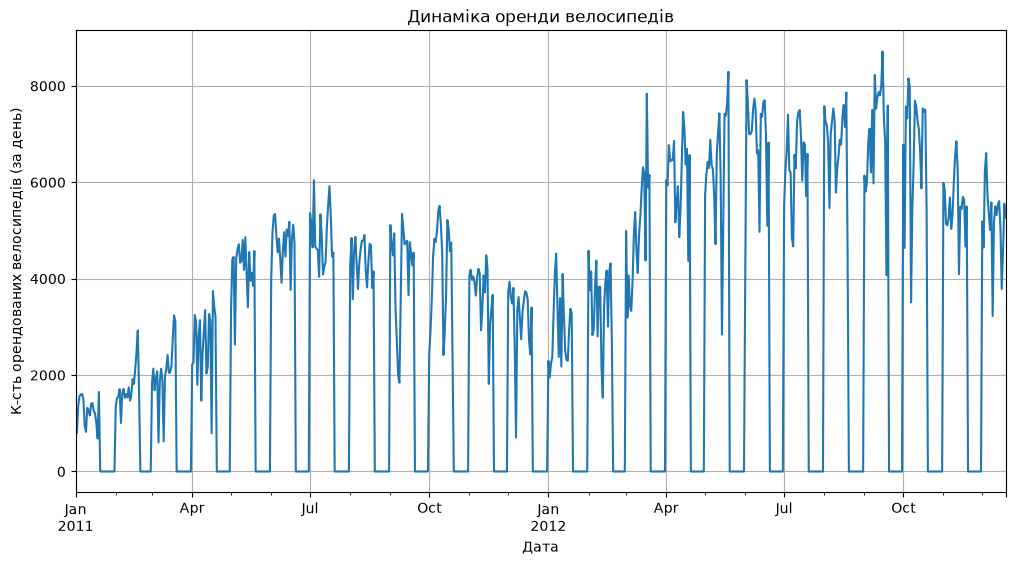

In [22]:
daily_count.plot(
    kind = 'line',
    #marker='o',
    figsize=(12, 6),
    title='Динаміка оренди велосипедів',
    xlabel='Дата',
    ylabel='К-сть орендованих велосипедів (за день)',
    grid=True
);

Можливі причини "заломів" на графіку
1. Щодня на оренду велосипедів впливають змінні фактори (погода, день тижня, свята), тому сусідні дні сильно відрізняються.
2. На графіку видно щомісячні повторювані провали до 0, що вказує на дні без зафіксованих оренд або відсутні/нульові значення. Це можна перевірити наступним чином:

In [23]:
daily_count.head(30)

datetime
2011-01-01     985
2011-01-02     801
2011-01-03    1349
2011-01-04    1562
2011-01-05    1600
2011-01-06    1606
2011-01-07    1510
2011-01-08     959
2011-01-09     822
2011-01-10    1321
2011-01-11    1263
2011-01-12    1162
2011-01-13    1406
2011-01-14    1421
2011-01-15    1248
2011-01-16    1204
2011-01-17    1000
2011-01-18     683
2011-01-19    1650
2011-01-20       0
2011-01-21       0
2011-01-22       0
2011-01-23       0
2011-01-24       0
2011-01-25       0
2011-01-26       0
2011-01-27       0
2011-01-28       0
2011-01-29       0
2011-01-30       0
Freq: D, Name: count, dtype: int64

In [29]:
df.index.day.max()

np.int32(19)

In [ ]:
Отже, після 19 числа дані відсутні, що спричиняє заломи. Як вихід можна заресемплити дані помісячно. Це прибере заломи та графік стане більш приємним.

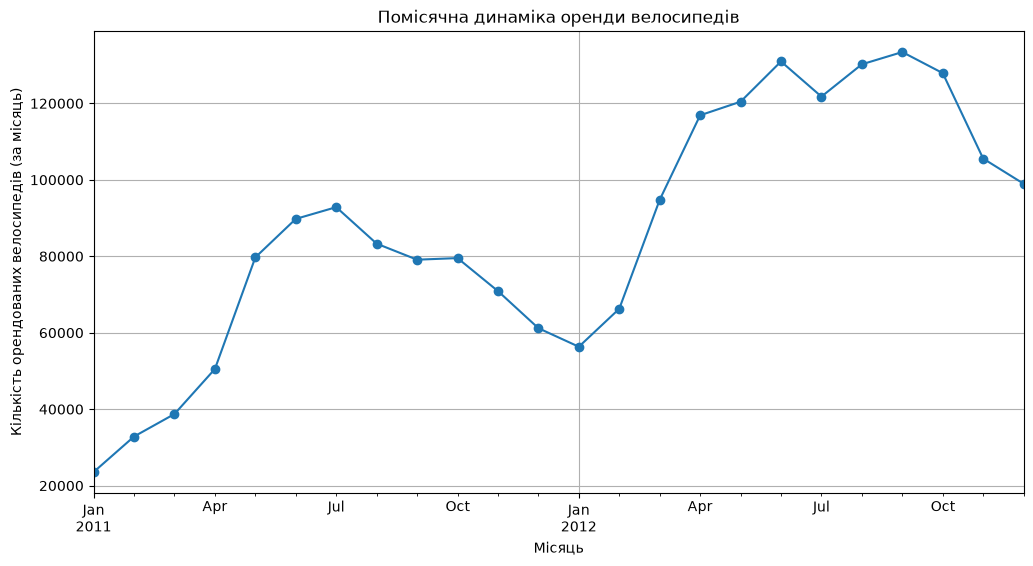

In [25]:
monthly_count = df['count'].resample('ME').sum()
monthly_count.plot(
    kind='line',
    marker='o',
    figsize=(12, 6),
    title='Помісячна динаміка оренди велосипедів',
    xlabel='Місяць',
    ylabel='Кількість орендованих велосипедів (за місяць)',
    grid=True
)
plt.show()

2. Загальна тенденція — зростання від початку 2011 року до 2012 року.
3. Так, чітко помітна хвилеподібна сезонність протягом кожного року:

- спад у холодніший період / наприкінці осені та взимку (мінімуми припадають на січень обох років — Jan 2011 і Jan 2012);

- підйом у тепліші місяці (з весни до літа/початку осені).

4. Аномально низькі показники можуть бути спричинені поганими погодними умовами. Аномально високі можливо спричинені якимись святами або іншими подіями.


## Завдання 2: Аналіз сезонності (Bar Plot)

**Завдання:**
Побудуйте вертикальну стовпчасту діаграму середньої кількості орендованих велосипедів за сезонами(кварталами). Додайте підписи осей і заголовок.

Просунуте доповнення:
1. Позначте квартали не числом, а назвою на візуалізації.
2. Додайте підписи над стовпцями зі значеннями в кожному стовпці.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В який квартал найбільша середня кількість оренди велосипедів?
2. Як ви можете пояснити таку сезонну закономірність?
3. У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми?

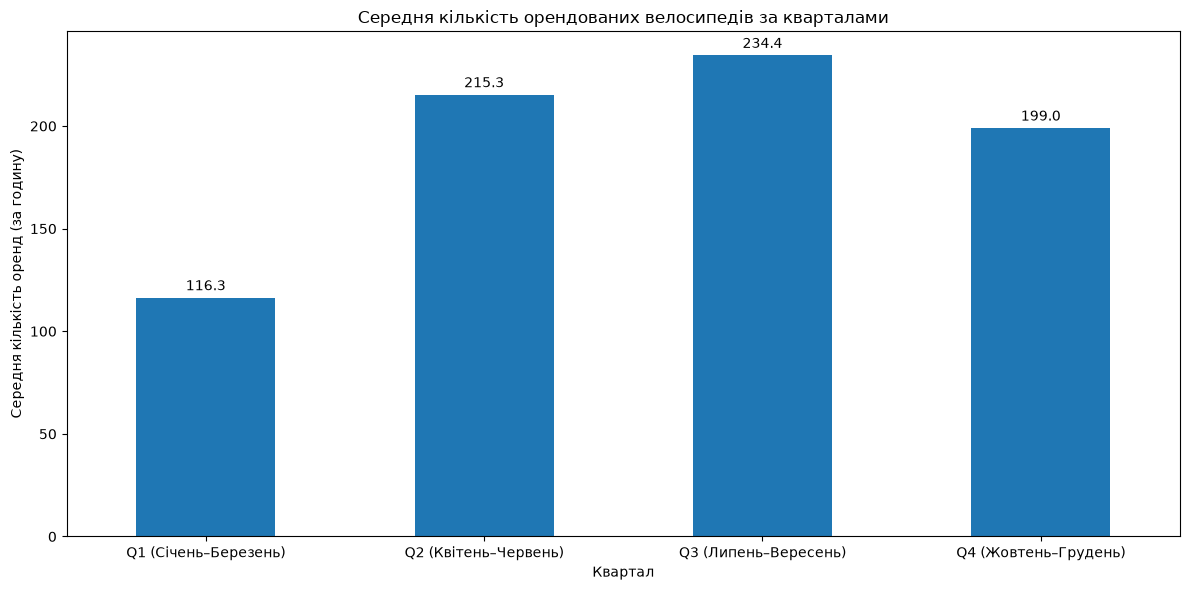

In [34]:
season_mean = df.groupby('season')['count'].mean().sort_index()

quarter_labels = {
    1: 'Q1 (Січень–Березень)',
    2: 'Q2 (Квітень–Червень)',
    3: 'Q3 (Липень–Вересень)',
    4: 'Q4 (Жовтень–Грудень)'
}

ax = season_mean.plot(
    kind='bar',
    figsize=(12, 6),
    title='Середня кількість орендованих велосипедів за кварталами',
    xlabel='Квартал',
    ylabel='Середня кількість оренд (за годину)',
    rot=0
)
ax.set_xticklabels([quarter_labels.get(idx, str(idx)) for idx in season_mean.index])

ax.bar_label(ax.containers[0], fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()

1. Найбільша середня кількість оренд припадає на 3-й квартал (Q3: липень–вересень) — у середньому 234.4 оренди за годину.
2. Сезонну закономірність можна пояснити теплішою погодою, комфортнішою температурою та більшою кількістю поїздок у теплі місяці порівняно з холоднішим періодом.
3. Різниця між найпопулярнішим і найменш популярним кварталами: середнє в Q3 (234.4) приблизно вдвічі (≈ 2.02 раза) вище, ніж у Q1 (116.3) — найменш популярному кварталу, де холодніше і попит на оренду помітно нижчий.

## Завдання 3: Динаміка за місяцями (Line Plot)

**Завдання:**
Створіть лінійний графік середньої кількості оренд велосипедів на годину по місяцях (тобто групування в рамках місяця і беремо середню кількість оренд у цей місяць з кількох років). Використайте маркери-кружечки для точок, додайте сітку та пофарбуйте лінію у червоний колір.

Просунуте доповнення:
- додайте аби по осі ОХ поділки були чітко на кожен окремий місяць по одній. Тобто сумарно 12 поділок.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які місяці спостерігається пік та спад оренди?
2. Чи збігається ця закономірність з результатами з попереднього завдання?
3. Як може вплинути клімат на оренду велосипедів протягом року?


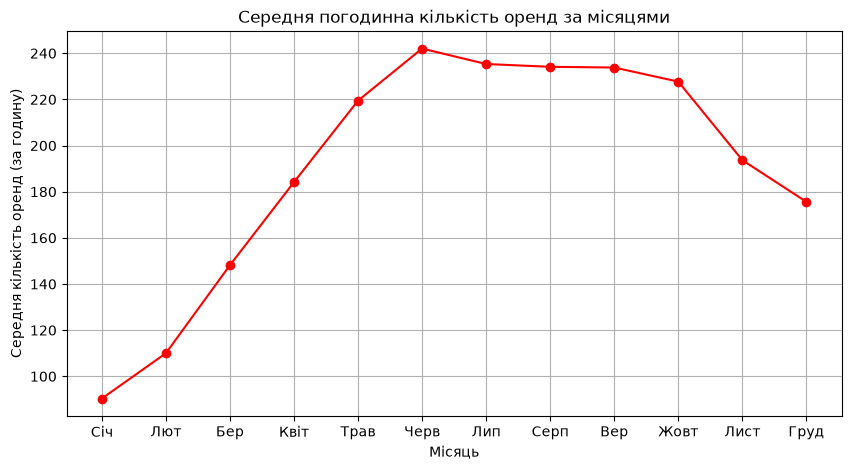

In [10]:
months = [
    'Січ',
    'Лют',
    'Бер',
    'Квіт',
    'Трав',
    'Черв',
    'Лип',
    'Серп',
    'Вер',
    'Жовт',
    'Лист',
    'Груд',
]

df.groupby('month')['count'].mean().reindex(range(1, 13)).set_axis(
    months
).plot(
    marker='o',
    color='red',
    grid=True,
    xticks=range(len(months)),
    xlabel='Місяць',
    ylabel='Середня кількість оренд (за годину)',
    title='Середня погодинна кількість оренд за місяцями',
    figsize=(10, 5),
)
plt.show()

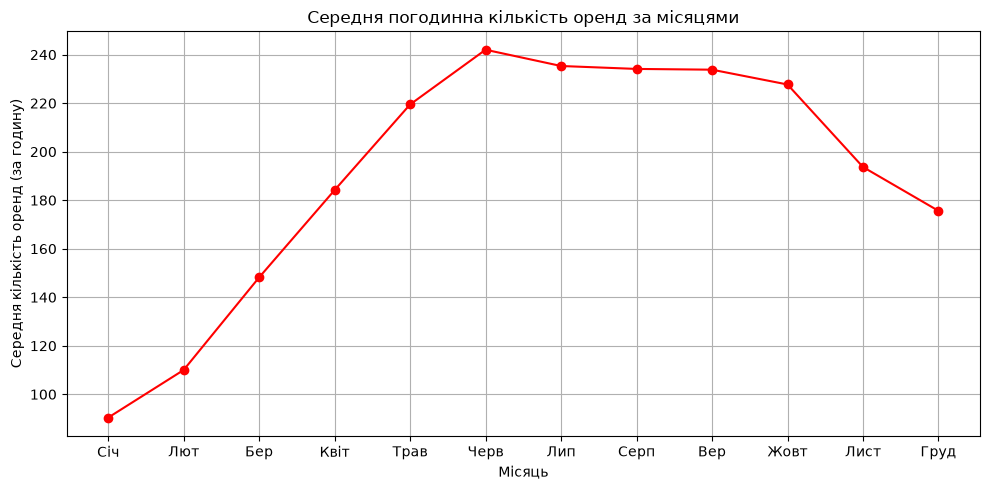

In [35]:
# monthly_avg = df.groupby(df.index.month)['count'].mean().sort_index()

# ax = monthly_avg.plot(
#     kind='line',
#     color='red',
#     marker='o',
#     figsize=(10, 5),
#     title='Середня погодинна кількість оренд за місяцями',
#     xlabel='Місяць',
#     ylabel='Середня кількість оренд (за годину)',
#     grid=True
# )

# ax.set_xticks(range(1, 13))
# ax.set_xticklabels(['Січ', 'Лют', 'Бер', 'Квіт', 'Трав', 'Черв', 'Лип', 'Серп', 'Вер', 'Жовт', 'Лист', 'Груд'])

# plt.tight_layout()
# plt.show()

1. Пік оренди спостерігається у літні місяці, а спад у зимні.
2. Так, збігається.
3. Взимку попит на оренду спадає через холод, навесні він підіймається з ростом температури та йде на свій пік улітку. Восени попит спадає з погіршенням погодних умов.

## Завдання 4: Розподіл погодних умов (Pie Chart)

**Завдання:**
1. Побудуйте кругову діаграму з часткою записів за погодними умовами
2. Додайте підписи з відсотками та легенду з описами погоди (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ).
3. Визначте свої відмінні від стандартних кольори для відображення кожної категорії.
4. Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. Яка погода переважає в датасеті?
2. Чи є дні із сильним дощем? Яка їх частка?
3. Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?

Очікуваний результат:

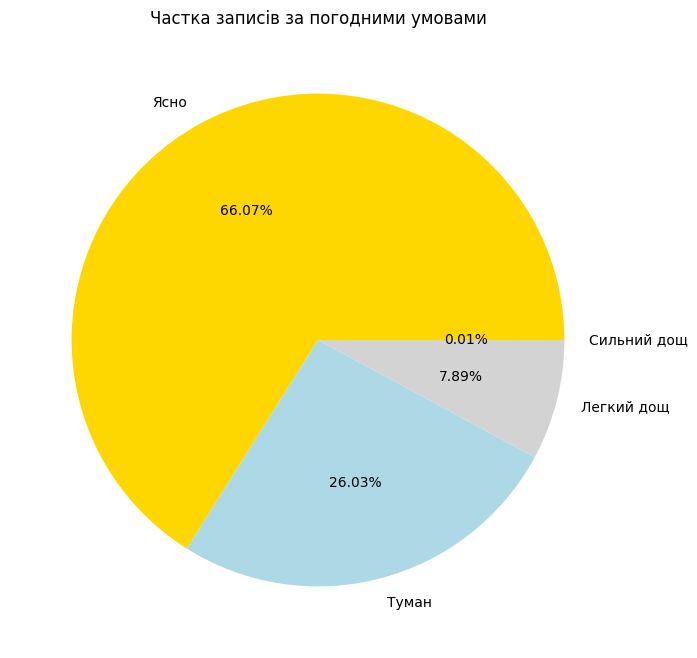

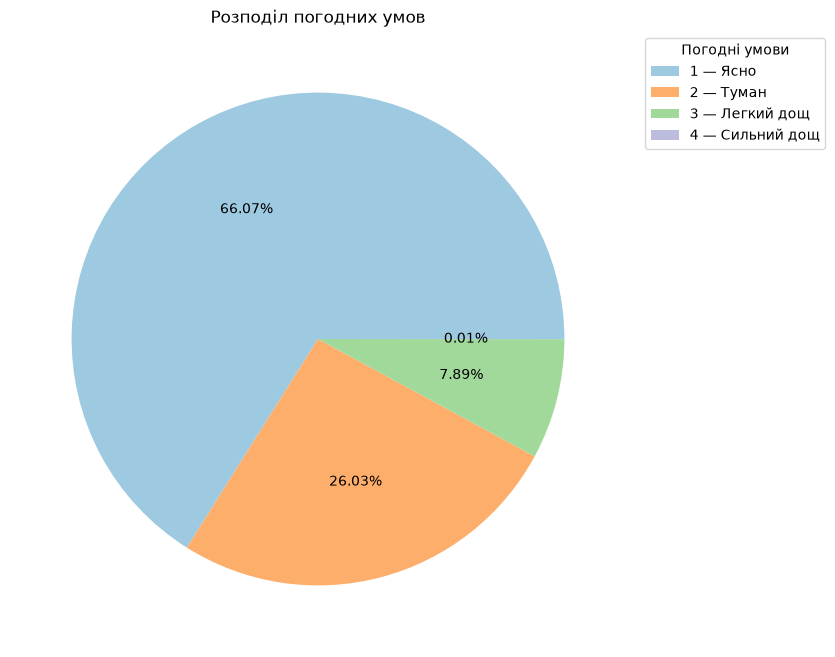

In [44]:
df['weather'].value_counts().sort_index().plot.pie(
    figsize=(8, 8),
    autopct='%1.2f%%',
    title='Розподіл погодних умов',
    labels=None,
    ylabel='',
    colors = [plt.cm.tab20c.colors[i] for i in [2, 6, 10, 14]]
)
plt.legend(
    ['1 — Ясно', '2 — Туман', '3 — Легкий дощ', '4 — Сильний дощ'],
    title='Погодні умови',
    loc='upper left',
    bbox_to_anchor=(1.02, 1)
)
plt.show()

1. У датасеті з великим відривом переважає ясна погода (1 — Ясно) — на неї припадає 66.1% усіх записів.
2. Такі записи в датасеті є (категорія 4 — Сильний дощ), але їхня частка мала (0,01%)
3. Ясна й спокійна погода створює найкомфортніші умови для поїздок і підтримує найвищий попит. Коли з'являється туман або легкий дощ, їхати стає менш зручно та безпечно, тому активність падає, а сильний дощ практично зупиняє поїздки просто неба

## Завдання 5: Box Plot для аналізу викидів

**Завдання:**
Створіть коробковий графік (box plot) кількості орендованих велосипедів для кожного типу погоди.

Просунуте доповнення:
- Використайте горизонтальну орієнтацію.
- Позначте погодні умови не числом, а назвою на візуалізації.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. При якій погоді найбільший розкид у кількості оренди?
2. Чи є викиди (outliers) в даних? При якій погоді?
3. При якій погоді медіанне значення оренди найвище?

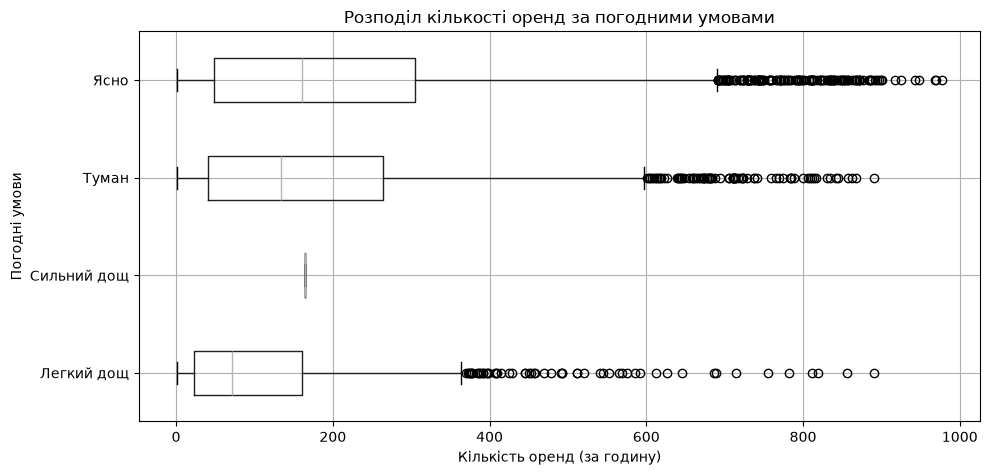

In [46]:
weather_labels = {
    1: 'Ясно',
    2: 'Туман',
    3: 'Легкий дощ',
    4: 'Сильний дощ'
}

ax = df.assign(weather_name=df['weather'].map(weather_labels)).boxplot(
    column='count',
    by='weather_name',
    vert=False,
    figsize=(10, 5),
    grid=True
)

plt.title('Розподіл кількості оренд за погодними умовами')
plt.suptitle('')
plt.xlabel('Кількість оренд (за годину)')
plt.ylabel('Погодні умови')

plt.tight_layout()
plt.show()

1. Найбільший розкид спостерігається при ясній погоді
2. Так, викидиВони спостерігаються у категоріях «Ясно» (найбільше, сягають майже ~1000 оренд/год), «Туман» (до ~900 оренд/год) та «Легкий дощ»(також до ~900 оренд/год)
3. Найвища медіана припадає на ясну погоду (Ясно) — приблизно 160 оренд за годину.

## Завдання 6: Кореляція температури та оренди (Scatter Plot)

**Завдання:**
Побудуйте діаграму розсіювання залежності між температурою (`temp`) та загальною кількістю оренди (`count`). Розфарбуйте точки за сезонами, додайте напівпрозорість (alpha=0.6).

**Увага!** За замовченням буде колір

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
- Чи є зв'язок між температурою та кількістю оренди? Який?

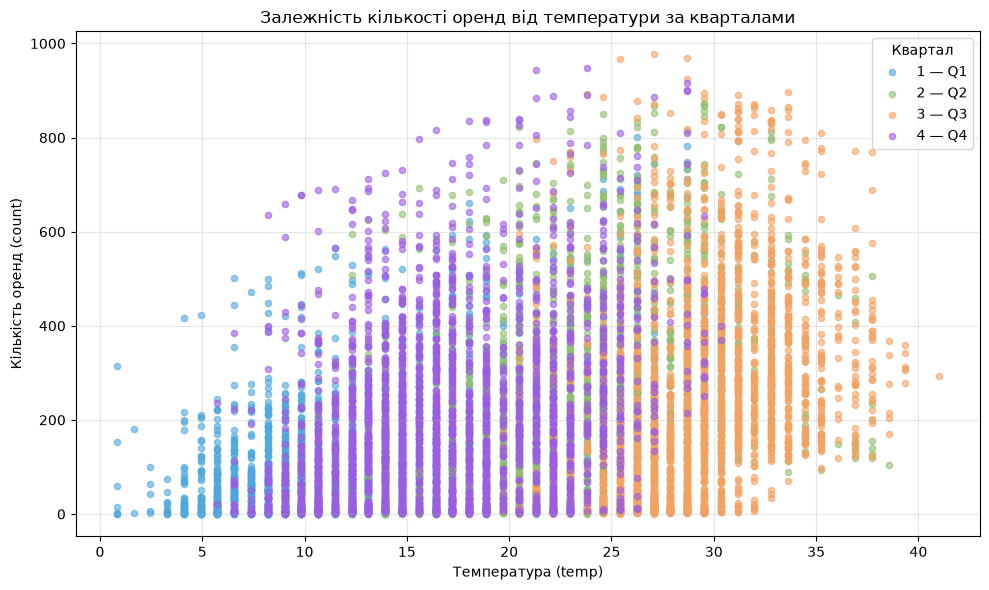

In [53]:
# season_labels = {
#     1: '1 — Q1',
#     2: '2 — Q2',
#     3: '3 — Q3',
#     4: '4 — Q4',
# }
# colors = ['#4EA8DE', '#90BE6D', '#F4A261', '#9B5DE5']

# ax = None
# for s, color in zip(sorted(df['season'].dropna().unique()), colors):
#   ax = df[df['season'] == s].plot.scatter(
#       x='temp',
#       y='count',
#       ax=ax,
#       alpha=0.6,
#       s=20,
#       color=color,
#       label=season_labels.get(s, str(s)),
#       figsize=(10, 6),
#   )

# ax.set(
#     title='Залежність кількості оренд від температури за кварталами',
#     xlabel='Температура (temp)',
#     ylabel='Кількість оренд (count)',
# )
# ax.legend(title='Квартал')
# ax.grid(True, alpha=0.3)

# plt.tight_layout()
# plt.show()

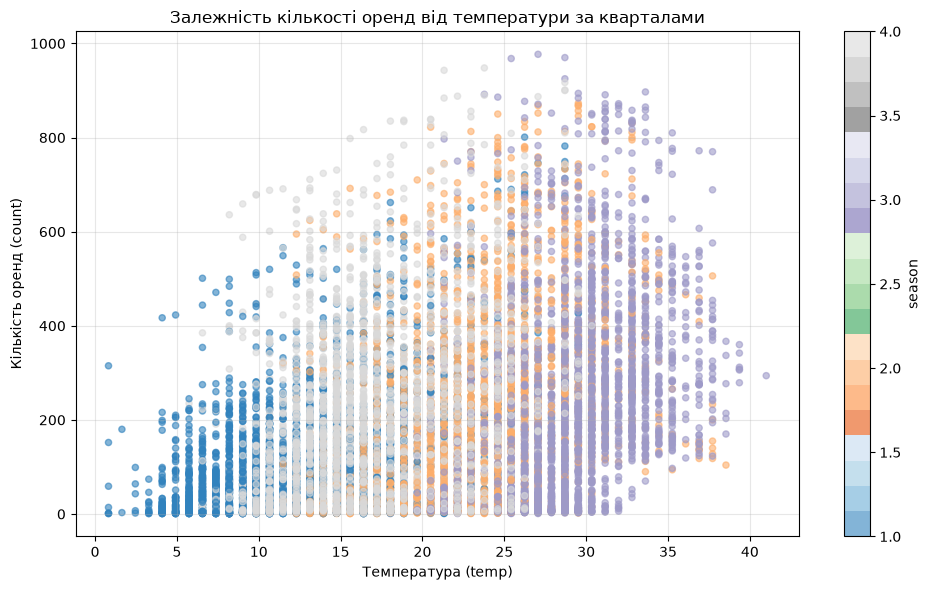

In [4]:
ax = df.plot.scatter(
    x='temp',
    y='count',
    c='season',
    cmap='tab20c',
    alpha=0.6,
    s=20,
    figsize=(10, 6),
    title='Залежність кількості оренд від температури за кварталами',
)
ax.set(xlabel='Температура (temp)', ylabel='Кількість оренд (count)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Простежується помірний позитивний зв’язок: у міру зростання температури загальний рівень оренд зазвичай підвищується. Водночас точки мають значний вертикальний розкид — навіть за однакової температури кількість оренд за годину може сильно відрізнятися, адже на попит паралельно впливають година доби, будні чи вихідні та погодні умови

## (Опціонально) Завдання 7: Порівняння користувачів (Stacked Bar Chart)

**Завдання:**
Ми хочемо дізнатись як по дням тижня беруть в середньому в оренду велосипеди випадкові і зареєстровані користувачі.

Створіть стовпчасту діаграму з накопиченням (bar з налаштуванням `stacked=True`), яка показує співвідношення випадкових (`casual`) та зареєстрованих (`registered`) користувачів по днях тижня за кількістю взятих ними велосипедів в оренду в середньому. Використайте різні кольори для типів користувачів.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які дні тижня більше оренд від зареєстрованих користувачів?
2. Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня?

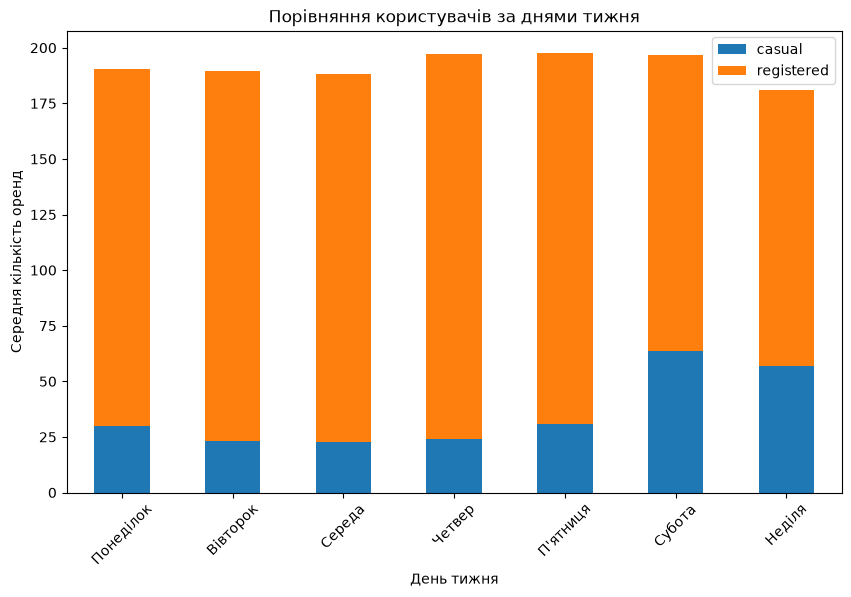

In [5]:
import matplotlib.pyplot as plt

week_avg = df.groupby('weekday_num')[['casual', 'registered']].mean()

ax = week_avg.plot.bar(
    stacked=True,
    figsize=(10, 6),
    title='Порівняння користувачів за днями тижня',
    xlabel='День тижня',
    ylabel='Середня кількість оренд',
)

ax.set_xticklabels([
    'Понеділок',
    'Вівторок',
    'Середа',
    'Четвер',
    "П'ятниця",
    'Субота',
    'Неділя',
])
plt.xticks(rotation=45)
plt.show()

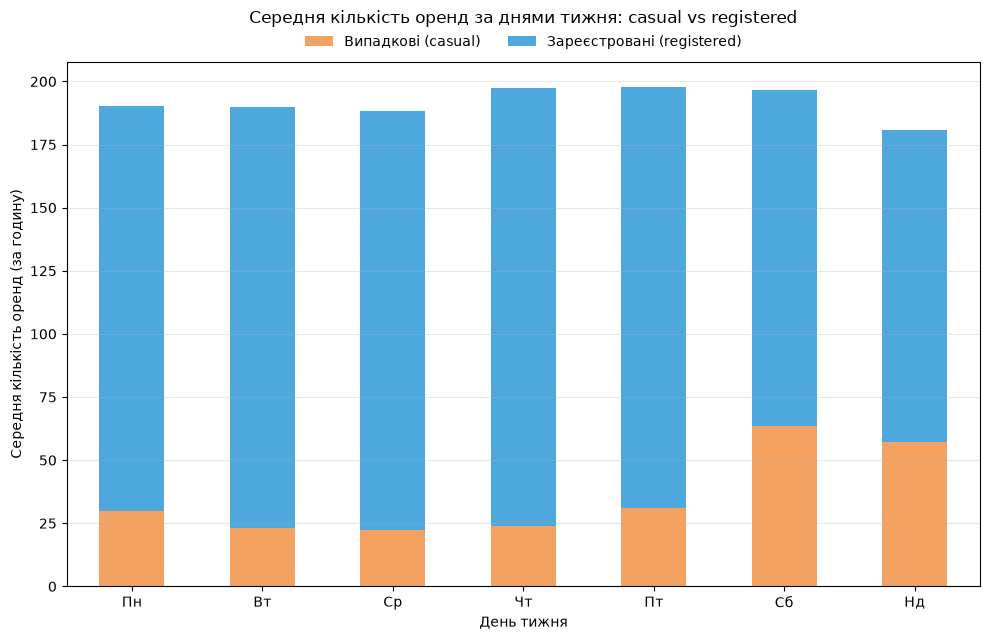

In [71]:
# day_col = 'weekday'

# day_labels = {
#     0: 'Пн',
#     1: 'Вт',
#     2: 'Ср',
#     3: 'Чт',
#     4: 'Пт',
#     5: 'Сб',
#     6: 'Нд',
# }

# grouped = (
#     df.groupby('weekday_num')[['casual', 'registered']]
#     .mean()
#     .rename(index=day_labels)
# )

# ax = grouped.plot.bar(
#     stacked=True,
#     figsize=(10, 6.5),
#     color=['#F4A261', '#4EA8DE'],
# )

# ax.set_title(
#     'Середня кількість оренд за днями тижня: casual vs registered',
#     pad=28,
# )
# ax.set_xlabel('День тижня')
# ax.set_ylabel('Середня кількість оренд (за годину)')
# ax.legend(
#     ['Випадкові (casual)', 'Зареєстровані (registered)'],
#     loc='lower center',
#     bbox_to_anchor=(0.5, 1.0),
#     ncol=2,
#     frameon=False,
# )
# ax.tick_params(axis='x', rotation=0)
# ax.grid(axis='y', alpha=0.3)

# plt.tight_layout()
# plt.show()

1. Найбільше оренд від зареєстрованих користувачів спостерігається у будні дні — особливо в четвер і п'ятницю.
2. Ця різниця добре пояснюється двома різними сценаріями використання сервісу:

Зареєстровані користувачі (registered) — це насамперед регулярні міські користувачі, які часто використовують велосипед для щоденних поїздок «у справах»: на роботу, навчання чи зустрічі в будні дні. У вихідні частина таких поїздок зникає, бо немає щоденного робочого маршруту.

Випадкові користувачі (casual) у будні беруть велосипеди рідко (близько 20–30/год), а в суботу та неділю їхня активність зростає більш ніж удвічі (до ~55–65/год). Це типова поведінка для прогулянок, відпочинку та туризму у вільний час, коли більше людей виходять покататися без прив'язки до робочого графіка.